In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob

from itertools import combinations
import sys
from statsmodels.stats.multitest import multipletests
from scipy.stats import norm
import os

## Prepare ENSEMBL+CHESS USE catalog

In [2]:
!mkdir "./gtfs"

In [3]:
%%time
#Rename chroms in ensembl
import pyranges as pr
df = pr.read_gtf('../../../arkuda_backup/gtfs/Homo_sapiens.GRCh38.108.chr.gtf.gz')

CPU times: total: 1min 10s
Wall time: 1min 10s


In [4]:
chroms = df.Chromosome.unique().tolist()

In [5]:
mapping = {i:'chrM' if i=='MT' else f'chr{i}' for i in chroms}
mapping

{'1': 'chr1',
 '2': 'chr2',
 '3': 'chr3',
 '4': 'chr4',
 '5': 'chr5',
 '6': 'chr6',
 '7': 'chr7',
 '8': 'chr8',
 '9': 'chr9',
 '10': 'chr10',
 '11': 'chr11',
 '12': 'chr12',
 '13': 'chr13',
 '14': 'chr14',
 '15': 'chr15',
 '16': 'chr16',
 '17': 'chr17',
 '18': 'chr18',
 '19': 'chr19',
 '20': 'chr20',
 '21': 'chr21',
 '22': 'chr22',
 'MT': 'chrM',
 'X': 'chrX',
 'Y': 'chrY'}

In [6]:
df.Chromosome = df.Chromosome.map(mapping)

In [7]:
df.to_gtf('./gtfs/Homo_sapiens.GRCh38.108.chr_chromnames.gtf')

In [8]:
cmd = 'wsl sh -c "gunzip -c ../../../arkuda_backup/gtfs/chess3.1.3.GRCh38.gtf.gz > ./gtfs/chess3.1.3.GRCh38.gtf"'
!{cmd}

In [9]:
!mkdir "./gtfs/merged"
exe = '/home/zavilev/soft/gffcompare/gffcompare'
ref = './gtfs/Homo_sapiens.GRCh38.108.chr_chromnames.gtf'
other = './gtfs/chess3.1.3.GRCh38.gtf'
prefix = './gtfs/merged/gffcompare'
command = f'{exe} -r {ref} -o {prefix} {other}'
cmd = f'wsl sh -c "{command}"'
print(cmd)

wsl sh -c "/home/zavilev/soft/gffcompare/gffcompare -r ./gtfs/Homo_sapiens.GRCh38.108.chr_chromnames.gtf -o ./gtfs/merged/gffcompare ./gtfs/chess3.1.3.GRCh38.gtf"


In [10]:
%%time
!{cmd}

CPU times: total: 594 ms
Wall time: 1min 43s


### Filter and merge GTFs

In [11]:
merged = pr.read_gtf('./gtfs/merged/gffcompare.annotated.gtf').df

In [12]:
merged.class_code.unique()

array(['=', nan, 'c', 'x', 'j', 'm', 'k', 'n', 'u', 'y', 'i', 'o', 'e',
       'p', 's'], dtype=object)

In [13]:
trgene = merged[merged.Feature=='transcript'][['transcript_id','gene_id','ref_gene_id']].copy()

In [14]:
trgene.gene_id = np.where(trgene.ref_gene_id.isna(),trgene.gene_id,trgene.ref_gene_id)

In [15]:
import csv
def read_gtf(file):
    df = pr.read_gtf(file).df
    c1 = ['Chromosome', 'Source', 'Feature', 'Start', 'End', 'Score', 'Strand', 'Frame']
    c2 = ['chrn', 'source', 'type', 'start', 'end', 'score', 'strand', 'frame']
    d = dict(zip(c1,c2))
    df = df.rename(columns=d)
    df.start+=1
    return df

def format_desc(row,*attrs):
    desc = [f'{attr} "{row[attr]}"' for attr in attrs if not pd.isnull(row[attr])]
    return '; '.join(desc)+';'

def write_annotation(x,file):
    df = x.copy()
    gtfcols = ['chrn', 'source', 'type', 'start', 'end', 'score', 'strand', 'frame' ,'desc']
    for col in set(gtfcols)-set(df.columns):
        df[col] = '.'
    attrs = [i for i in df.columns if i not in gtfcols]
    df['desc'] = df.apply(format_desc,axis=1,args=attrs)
    return df[gtfcols].to_csv(file,sep='\t',index=False,header=False,quoting=csv.QUOTE_NONE)

In [16]:
chess = read_gtf('./gtfs/chess3.1.3.GRCh38.gtf')

In [17]:
filt = trgene.drop('ref_gene_id',axis=1).merge(chess.drop('gene_id',axis=1))

In [18]:
filt[filt.type=='transcript'].gene_id.str.startswith('ENSG').value_counts()

gene_id
True     145716
False     22735
Name: count, dtype: int64

In [19]:
cols = ['chrn', 'source', 'type', 'start', 'end', 'score', 'strand', 'frame' ,'desc', 'gene_id','transcript_id']
filt = filt[filt.columns.intersection(cols)]

In [20]:
%%time
write_annotation(filt,'./gtfs/chess_filtered.gtf')

CPU times: total: 43.8 s
Wall time: 44.3 s


In [21]:
df.tag.unique()

array([nan, 'MANE_Select', 'basic', 'Ensembl_canonical', 'mRNA_start_NF',
       'mRNA_end_NF', 'CCDS', 'seleno', 'MANE_Plus_Clinical'],
      dtype=object)

In [22]:
bad_tags = ['mRNA_start_NF', 'mRNA_end_NF']
df = df[~df.tag.isin(bad_tags)]

In [23]:
df.to_gtf('./gtfs/ensembl_filtered.gtf')

In [24]:
!wsl sh -c "cat ./gtfs/ensembl_filtered.gtf ./gtfs/chess_filtered.gtf > ./gtfs/merged/merged_filtered.gtf"

### Run NMDj separately for ensembl and chess, then union
Because chess contains many NMD-like transcripts with alternative start (which prevents detection of NMD transcripts from ensembl if gtfs are united)

In [25]:
python = r'C:\Users\zavil\miniconda3\envs\oldpandas\python.exe'
exe = f'{python} ../../../arkuda_backup/nmdj_paper/v1.1/NMDj/scripts/NMDj.py'
gtf = './gtfs/chess_filtered.gtf'
prefix = './use_catalog/chess/'

cmd = f'{exe} -g {gtf} -n -p {prefix} --threads 10'
print(cmd)

C:\Users\zavil\miniconda3\envs\oldpandas\python.exe ../../../arkuda_backup/nmdj_paper/v1.1/NMDj/scripts/NMDj.py -g ./gtfs/chess_filtered.gtf -n -p ./use_catalog/chess/ --threads 10


In [26]:
!{cmd}

Loading GTF...
input GTF loaded, time: 0.26 min
NMDTs found and written to ./use_catalog/chess/NMD_annotation.tsv, time: 0.54 min
GTF filtered, time: 0.55 min
reading frames calculated, time: 0.65 min
Starting to search for CJs...
tasks created, time: 0.9 min
Done 1000 transcripts, time: 0.92 min
Done 2000 transcripts, time: 1.0 min
Done 3000 transcripts, time: 1.15 min
Done 4000 transcripts, time: 1.29 min
Done 5000 transcripts, time: 1.43 min
Done 6000 transcripts, time: 1.58 min
Done 7000 transcripts, time: 1.72 min
Done 8000 transcripts, time: 1.86 min
CJs found, time: 2.03 min
CJs clustered and written to ./use_catalog/chess/junctions.tsv, time: 2.26 min
Reference transcript set is not specified. Gonna use all coding transcripts as a reference
Transcript structures in event regions written to ./use_catalog/chess/transcript_structures.tsv
Event classification written to ./use_catalog/chess/classification.tsv, time: 2.41 min
error in ENSG00000072840_1
tasks created, time: 2.44 min
D

In [27]:
python = r'C:\Users\zavil\miniconda3\envs\oldpandas\python.exe'
exe = f'{python} ../../../arkuda_backup/nmdj_paper/v1.1/NMDj/scripts/NMDj.py'
gtf = './gtfs/ensembl_filtered.gtf'
prefix = './use_catalog/ensembl/'

cmd = f'{exe} -g {gtf} -p {prefix} --threads 10 --disable_cds'
print(cmd)

C:\Users\zavil\miniconda3\envs\oldpandas\python.exe ../../../arkuda_backup/nmdj_paper/v1.1/NMDj/scripts/NMDj.py -g ./gtfs/ensembl_filtered.gtf -p ./use_catalog/ensembl/ --threads 10 --disable_cds


In [28]:
!{cmd}

Loading GTF...
input GTF loaded, time: 1.24 min
GTF filtered, time: 1.45 min
reading frames calculated, time: 1.59 min
Starting to search for CJs...
tasks created, time: 1.96 min
Done 1000 transcripts, time: 1.98 min
Done 2000 transcripts, time: 1.99 min
Done 3000 transcripts, time: 2.06 min
Done 4000 transcripts, time: 2.2 min
Done 5000 transcripts, time: 2.33 min
Done 6000 transcripts, time: 2.47 min
ENST00000477160
single positional indexer is out-of-bounds
Done 7000 transcripts, time: 2.61 min
Done 8000 transcripts, time: 2.75 min
Done 9000 transcripts, time: 2.88 min
Done 10000 transcripts, time: 3.02 min
Done 11000 transcripts, time: 3.16 min
Done 12000 transcripts, time: 3.3 min
Done 13000 transcripts, time: 3.43 min
Done 14000 transcripts, time: 3.57 min
Done 15000 transcripts, time: 3.71 min
CJs found, time: 3.87 min
CJs clustered and written to ./use_catalog/ensembl/junctions.tsv, time: 4.26 min
Reference transcript set is not specified. Gonna use all coding transcripts as a 

#### Join catalogs

In [29]:
chess = pd.read_csv('./use_catalog/chess/catalog.tsv',sep='\t')
ensembl = pd.read_csv('./use_catalog/ensembl/catalog.tsv',sep='\t')

cols = ['gene_id','event_id']
aa = chess[chess.transcript_biotype=='nonsense_mediated_decay'].groupby(cols,observed=True,as_index=False).long_id.agg(set)
bb = ensembl[ensembl.transcript_biotype=='nonsense_mediated_decay'].groupby(cols,observed=True,as_index=False).long_id.agg(set)
m = aa.rename(columns={'event_id':'chess_id','long_id':'chess_long_id'}).merge(bb)

In [30]:
m['n_ensem'] = m.long_id.map(len)
m['n_chess'] = m.chess_long_id.map(len)
m['n_common'] = m.apply(lambda x: len(x.long_id&x.chess_long_id),axis=1)

In [31]:
chess.event_id.nunique(),ensembl.event_id.nunique()

(5009, 10827)

In [32]:
dupl = m[m.n_common>0]
dupl = dupl[(dupl.n_chess-1<=dupl.n_common)&(dupl.n_ensem-1<=dupl.n_common)]

In [33]:
dupl[['n_ensem','n_chess','n_common']].value_counts()

n_ensem  n_chess  n_common
1        1        1           795
2        2        2           322
         1        1            64
3        2        2            32
1        2        1            21
2        2        1            15
         3        2            15
3        3        3             9
                  2             2
         4        3             2
4        4        4             1
Name: count, dtype: int64

In [34]:
chessf = chess[~chess.event_id.isin(dupl.chess_id)].copy()
chessf.event_id.nunique()

3731

In [35]:
chessf.event_id.drop_duplicates().str.startswith('CHS').value_counts()

event_id
False    3604
True      127
Name: count, dtype: int64

In [36]:
chessf['src'] = 'chess'
ensembl['src'] = 'ensembl'
catalog = pd.concat([ensembl,chessf])

In [37]:
cols = ['src', 'gene_id', 'event_id', 'interval_start', 'interval_end', 'nmd_id_list',
       'coding_id_list', 'VIP', 'event_type', 'transcript_biotype', 'jtype', 'long_id', 'coef']
catalog = catalog[cols]
catalog.head(1)

,src,gene_id,event_id,interval_start,interval_end,nmd_id_list,coding_id_list,VIP,event_type,transcript_biotype,jtype,long_id,coef
0,ensembl,ENSG00000006071,ENSG00000006071_10,17431024,17432204,"ENST00000646993, ENST00000682288, ENST00000684711","ENST00000302539, ENST00000389817, ENST00000642...",DAD:DAD|DADADA:DA|complex,A3SS|PE2|complex,protein_coding,j,chr11_17428405_17432204_-,1.0


In [38]:
catalog.to_csv('./use_catalog/filtered_catalog.tsv',sep='\t',index=False)

## Prepare data

In [39]:
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')

In [40]:
getpsi = '../../../arkuda_backup/unproductive_splicing/data/TCGA/scripts/get_psi.py'
cmd = f"python {getpsi} -h"
!{cmd}

usage: get_psi.py [-h] -c C -j J [J ...] [-s S [S ...]] -o O [-t T]
                  [--step STEP] [--event EVENT [EVENT ...]]
                  [--groupcol GROUPCOL] [--numerator NUMERATOR]

options:
  -h, --help            show this help message and exit
  -c C                  path to catalog of junctions
  -j J [J ...]          pyIPSA J6 files
  -s S [S ...]          pyIPSA S6 files
  -o O                  output file
  -t T                  number of threads
  --step STEP           step to print info
  --event EVENT [EVENT ...]
                        colname(s) of event id
  --groupcol GROUPCOL   colname defining 2 groups for PSI calculation
  --numerator NUMERATOR
                        a group name in column "--groupcol" which will be
                        presented in numerator of PSI


### HeLa NMD KDs: upf1, smg6, smg7

In [41]:
catalog = './use_catalog/filtered_catalog.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/ensembl_chess.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay"
cmd

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi already exists.


'python ../../../arkuda_backup/unproductive_splicing/data/TCGA/scripts/get_psi.py -c ./use_catalog/filtered_catalog.tsv -j ../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/J6/*.J6.gz -s ../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/S6/*.S6.gz -o ../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/ensembl_chess.psi -t 5 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay'

In [42]:
!{cmd}

#-----starting parallel extraction of counts
0 columns processed, time since start: 1.8801605701446533
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.657376766204834
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [43]:
catalog = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/binASE.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/binASE.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_type --numerator inclusion"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.8718962669372559
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.6865768432617188
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [44]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)

In [45]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/metadata/NMDKD_all.tsv',sep='\t')
df = meta.merge(psi)
df = df.groupby(['group','experiment','src','event_id'],as_index=False,observed=True,sort=False)[['denom','num']].agg('mean')
df['psi'] = df.num/df.denom
df = df.pivot(index=['experiment','src','event_id'],columns = 'group', values=['psi','denom'])
df = df[(df.denom>15).all(1)].copy()
df['dpsi'] = df.psi.exp-df.psi.ctrl
df = df[df.dpsi!=0].copy()

In [46]:
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [47]:
df.experiment.value_counts()

experiment
HeLa_dKD        6557
HeLa_UPF1_KD    5261
HeLa_SMG6_KD    5112
HeLa_SMG7_KD    4988
Name: count, dtype: int64

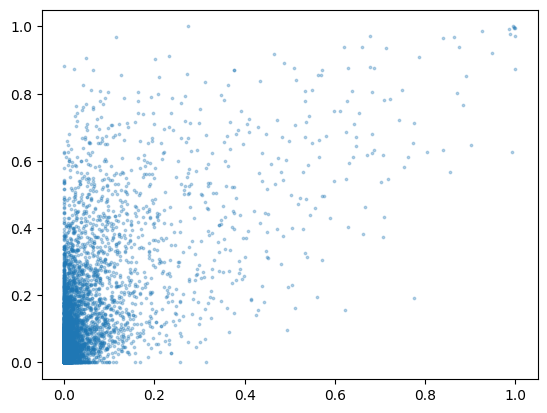

In [48]:
tmp = df[df.experiment=='HeLa_dKD']
plt.scatter(tmp.ctrl_psi,tmp.exp_psi,s=3,alpha=0.3)

In [49]:
!mkdir nmd_inactivation_data
df.to_csv('nmd_inactivation_data/hela_kd.tsv',sep='\t',index=False)

In [50]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/GSE86148_NMD_KD/psi/binASE.psi',
                  index_col=[0],comment='#',dtype=dtype)

In [51]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/metadata/NMDKD_all.tsv',sep='\t')
df = meta.merge(psi)
df = df.groupby(['group','experiment','src','event_id'],as_index=False,observed=True,sort=False)[['denom','num']].agg('mean')
df['psi'] = df.num/df.denom
df = df.pivot(index=['experiment','src','event_id'],columns = 'group', values=['psi','denom'])
df = df[(df.denom>15).all(1)].copy()
df['dpsi'] = df.psi.exp-df.psi.ctrl
df = df[df.dpsi!=0].copy()

In [52]:
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [53]:
df.experiment.value_counts()

experiment
HeLa_dKD        3411
HeLa_SMG7_KD    3299
HeLa_UPF1_KD    3180
HeLa_SMG6_KD    3104
Name: count, dtype: int64

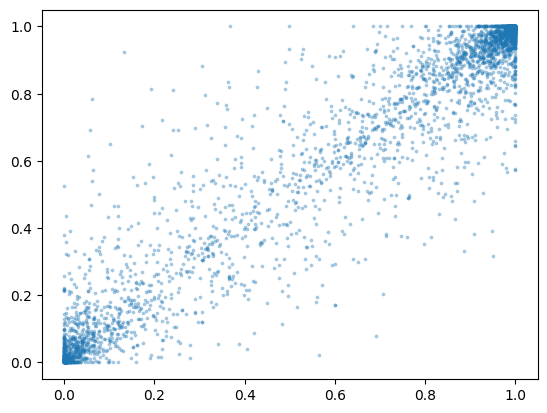

In [54]:
tmp = df[df.experiment=='HeLa_dKD']
plt.scatter(tmp.ctrl_psi,tmp.exp_psi,s=3,alpha=0.3)

In [55]:
df.to_csv('nmd_inactivation_data/hela_kd_binASE.tsv',sep='\t',index=False)

In [56]:
df.experiment.unique()

array(['HeLa_SMG6_KD', 'HeLa_SMG7_KD', 'HeLa_UPF1_KD', 'HeLa_dKD'],
      dtype=object)

### HeLa CHX

In [57]:
catalog = './use_catalog/filtered_catalog.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi/ensembl_chess.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.9359402656555176
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.7742788791656494
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [58]:
catalog = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/binASE.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi/binASE.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 5 --event src event_id --groupcol transcript_type --numerator inclusion"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 1.831960916519165
#-----starting parallel extraction of counts
0 columns processed, time since start: 1.773327112197876
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [59]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/meta.csv')
meta = meta[(meta.treatment.isin(['control','CHX']))&(meta['Assay Type']=='RNA-Seq')].copy()

meta['experiment'] = 'hela_chx'

meta['sample_type'] = np.where(meta.treatment=='control','ctrl','exp')
meta = meta[meta.time!='15 min'].copy()

meta = meta.rename(columns={'Run':'sample_id'})[['sample_id','experiment','sample_type']]

In [60]:
#these bam files were used as input to featurecounts on other machine
samples = meta.sample_id
paths = [f'/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/{sample}/Aligned.sortedByCoord.out.bam' for sample in samples]
'("'+'" "'.join(paths)+'")'

'("/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR8443314/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR8443315/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR8443318/Aligned.sortedByCoord.out.bam" "/gss/dplab/data/RIPiT-HEK293/GRCh38/bam/batch1/SRR8443319/Aligned.sortedByCoord.out.bam")'

In [61]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df).groupby(['src','event_id','experiment','sample_type'],observed=True)[['psi','denom']].agg('mean')

df = df[df.denom>15].reset_index().pivot(index = ['src','event_id','experiment'],columns='sample_type',values=['psi','denom'])

df = df[(df.psi[['ctrl','exp']].notna().all(1))&(df.psi.ctrl!=df.psi.exp)]
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index().copy()

In [62]:
df.experiment.unique()

array(['hela_chx'], dtype=object)

In [63]:
df.to_csv('nmd_inactivation_data/hela_chx.tsv',sep='\t',index=False)

In [64]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/psi/binASE.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df).groupby(['src','event_id','experiment','sample_type'],observed=True)[['psi','denom']].agg('mean')

df = df[df.denom>15].reset_index().pivot(index = ['src','event_id','experiment'],columns='sample_type',values=['psi','denom'])

df = df[(df.psi[['ctrl','exp']].notna().all(1))&(df.psi.ctrl!=df.psi.exp)]
d = {('psi', 'ctrl'):'ctrl_psi',
 ('psi', 'exp'):'exp_psi',
 ('denom', 'ctrl'):'ctrl_denom',
 ('denom', 'exp'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index().copy()

In [65]:
df.to_csv('nmd_inactivation_data/hela_chx_binASE.tsv',sep='\t',index=False)

In [66]:
df['dpsi'] = df.exp_psi-df.ctrl_psi

In [67]:
df.dpsi.describe()

count    769.000000
mean      -0.001692
std        0.120082
min       -0.457002
25%       -0.059524
50%       -0.001504
75%        0.055195
max        0.646944
Name: dpsi, dtype: float64

<Axes: xlabel='dpsi', ylabel='Density'>

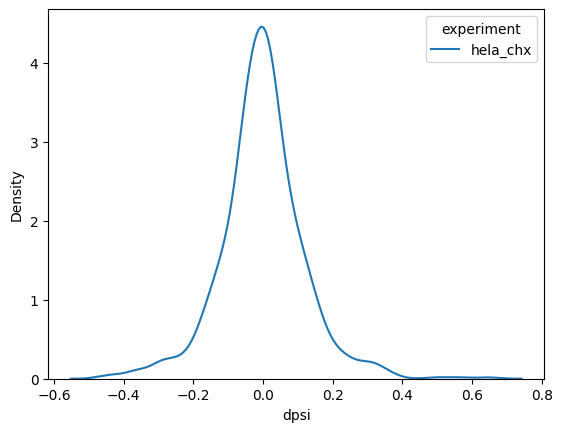

In [68]:
sns.kdeplot(data=df,x='dpsi',hue='experiment',common_norm=False)

#### HeLa chx (24h) logFC

In [69]:
# Counts were obtained by featurecounts on another machine
!wsl cp -r "../nmd_inactivation_data/gene_counts" "./nmd_inactivation_data/"

In [70]:
!wsl cp -r "../nmd_inactivation_data/deseq_res" "./nmd_inactivation_data/"

In [71]:
df = pd.read_csv('./nmd_inactivation_data/gene_counts/hela_chx.txt',sep='\t',comment='#')

df['gene_id'] = df.Geneid.apply(lambda x: x.split('.')[0])
df = df.drop(['Geneid','Chr','Start','End','Strand','Length'],axis=1)

In [72]:
df = df.groupby('gene_id').agg('sum')

In [73]:
df.columns = [os.path.basename(os.path.dirname(i)) for i in df.columns]

In [74]:
aa = df.min(axis=1)

In [75]:
aa = (df.quantile(0.2,axis=1)>10)
df = df.loc[aa]

In [76]:
def get_sf(expr,pseudo=1):
    ref = np.log(expr).apply(np.mean,1).apply(np.exp)
    sf = expr.div(ref,axis=0).apply(np.median)
    return sf

sf = get_sf(df)
expr = df.div(sf)

In [77]:
sf

SRR8443314    1.056298
SRR8443315    0.900269
SRR8443316    0.919712
SRR8443317    0.914250
SRR8443318    1.134793
SRR8443319    1.116140
dtype: float64

In [78]:
expr = expr.reset_index().melt(id_vars='gene_id',var_name='sample_id',value_name='expr')

In [79]:
lfc = meta.merge(expr).groupby(['sample_type','gene_id'],as_index=False).expr.agg('mean')
lfc = lfc.pivot(index=['gene_id'],columns='sample_type',values='expr')

In [80]:
lfc = lfc[(lfc.ctrl>10)&(lfc.exp>10)].copy()
lfc['log2FoldChange']  = np.log2(lfc.exp/lfc.ctrl)

In [81]:
aa = lfc[['log2FoldChange']]
aa = aa.reset_index()
aa

sample_type,gene_id,log2FoldChange
0,ENSG00000000003,-1.201393
1,ENSG00000000419,1.076415
2,ENSG00000000457,1.433791
3,ENSG00000000460,1.583727
4,ENSG00000001036,-1.362895
...,...,...
12411,ENSG00000291223,-0.363588
12412,ENSG00000291224,-0.149568
12413,ENSG00000291228,1.475069
12414,ENSG00000291234,-0.246220


In [82]:
aa.to_csv('./nmd_inactivation_data/deseq_res/HeLa_chx.tsv',sep='\t',index=False)

### Nuclear-cytosolic fractioning

In [83]:
catalog = './use_catalog/filtered_catalog.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi/ensembl_chess.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 10 --event src event_id --groupcol transcript_biotype --numerator nonsense_mediated_decay"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 2.850271463394165
#-----starting parallel extraction of counts
0 columns processed, time since start: 2.74684739112854
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [84]:
catalog = '../../../arkuda_backup/unproductive_splicing/data/TCGA/input/catalogs/binASE.tsv'
J6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/pyIPSA/J6/*.J6.gz'
S6 = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/pyIPSA/S6/*.S6.gz'
out = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi/binASE.psi'
path = f'"{os.path.dirname(out)}"'
!mkdir {path}
cmd = f"python {getpsi} -c {catalog} -j {J6} -s {S6} -o {out} -t 10 --event src event_id --groupcol transcript_type --numerator inclusion"
!{cmd}

A subdirectory or file ../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi already exists.


#-----starting parallel extraction of counts
0 columns processed, time since start: 2.6455001831054688
#-----starting parallel extraction of counts
0 columns processed, time since start: 2.537233352661133
Joining J6 and S6 results...
Calculating PSI...
Writing to file...


In [85]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed.csv').rename(columns={'fname':'sample_id'}).drop('replicate',axis=1)

In [86]:
meta['experiment'] = 'fractioning_'+meta.cell_line

In [87]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi/ensembl_chess.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df).groupby(['src','event_id','experiment','cellular_component'],observed=True)[['psi','denom']].agg('mean')

df = df[df.denom>15].reset_index().pivot(index = ['src','event_id','experiment'],
                                         columns='cellular_component',values=['psi','denom'])

df = df[df.notna().all(1)].copy()
df = df[df.psi.cytosol!=df.psi.nucleus]

d = {('psi', 'cytosol'):'ctrl_psi',
 ('psi', 'nucleus'):'exp_psi',
 ('denom', 'cytosol'):'ctrl_denom',
 ('denom', 'nucleus'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [88]:
df.to_csv('nmd_inactivation_data/fractioning.tsv',sep='\t',index=False)

In [89]:
dtype = {'src':'category','event_id':"category", 'sample_id':"category", 'num':float, 'denom':float}
psi = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/psi/binASE.psi',
                  index_col=[0],comment='#',dtype=dtype)
df = meta.merge(psi)
df['psi'] = df.num/df.denom
df = meta.merge(df).groupby(['src','event_id','experiment','cellular_component'],observed=True)[['psi','denom']].agg('mean')

df = df[df.denom>15].reset_index().pivot(index = ['src','event_id','experiment'],
                                         columns='cellular_component',values=['psi','denom'])

df = df[df.notna().all(1)].copy()
df = df[df.psi.cytosol!=df.psi.nucleus]

d = {('psi', 'cytosol'):'ctrl_psi',
 ('psi', 'nucleus'):'exp_psi',
 ('denom', 'cytosol'):'ctrl_denom',
 ('denom', 'nucleus'):'exp_denom'}

df.columns = df.columns.map(d)
df = df[d.values()].reset_index()

In [90]:
df.to_csv('nmd_inactivation_data/fractioning_binASE.tsv',sep='\t',index=False)

#### Expression

In [91]:
file = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed.csv'
meta = pd.read_csv(file)
meta = meta.rename(columns={'fname':'sample_id'}).drop('replicate',axis=1)

In [92]:
pe = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed-PE.csv'
se = '../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed-SE.csv'
pe = pd.read_csv(pe)
se = pd.read_csv(se)

In [93]:
pe_samples = set(pe.dbxrefs)
se_samples = set(se.dbxrefs)
all_samples = set(meta.sample_id)

In [94]:
se

,File accession,Experiment accession,Biosample term name,Run type,Biological replicate(s),dbxrefs
0,ENCFF000LSY,ENCSR000BZV,K562,single-ended,1,SRR5210711


In [95]:
pe_samples&se_samples

set()

In [96]:
all_samples-(pe_samples|se_samples)

set()

In [97]:
all_samples==(pe_samples|se_samples)

True

In [98]:
def mask(sample):
    return f'"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/{sample}/Aligned.sortedByCoord.out.bam"'
files  = [mask(i) for i in pe_samples]

In [99]:
# these files were used as input to featurecounts on another machine
print('files=(')
print('\n'.join(files))
print(')')

files=(
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR4421920/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR4422652/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR3192491/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR4421722/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR3192626/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR3192485/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR3192486/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCODE/nuclear-cytosolic-RNAseq/GRCh38/bam/batch1/SRR3192627/Aligned.sortedByCoord.out.bam"
"/gss/dplab/data/Standalone/ENCO

#### logFC

In [100]:
df = pd.read_csv('./nmd_inactivation_data/gene_counts/fractioning.txt',sep='\t',comment='#')

df['gene_id'] = df.Geneid.apply(lambda x: x.split('.')[0])
df = df.drop(['Geneid','Chr','Start','End','Strand','Length'],axis=1)

In [101]:
df = df.groupby('gene_id').agg('sum')

In [102]:
df.columns = [os.path.basename(os.path.dirname(i)) for i in df.columns]

In [103]:
def get_sf(expr,pseudo=1):
    ref = np.log(expr).apply(np.mean,1).apply(np.exp)
    sf = expr.div(ref,axis=0).apply(np.median)
    return sf

In [104]:
def get_lfc(x,meta):
    df = x.copy()
    cols = df.columns.intersection(meta.sample_id.unique())
    df = df[cols]
    df = df[(df>10).all(1)]
    print(f'#genes = {len(df)}')
    sf = get_sf(df)
    expr = df.div(sf)
    samples = meta[meta.sample_id.isin(cols)].groupby('cellular_component').sample_id.agg(list)
    exper = expr[samples.nucleus].mean(axis=1)
    ctrl = expr[samples.cytosol].mean(axis=1)
    print('SF:', sf.tolist())
    lfc = np.log2(exper/ctrl)
    lfc = lfc.reset_index()
    lfc.columns=['gene_id','log2FoldChange']
    return lfc

In [105]:
meta = meta[meta.cell_line.isin(['HepG2','K562'])].copy()

In [106]:
res = []
for key,submeta in meta.groupby('cell_line'):
    print(key)
    lfc = get_lfc(df,submeta)
    lfc['experiment'] = f'fractioning_{key}'
    res.append(lfc)

HepG2
#genes = 11566


SF: [0.8561315776379916, 0.3147419061335661, 0.814262500371751, 1.772161732657052, 1.7839711265462825, 1.611634842648865, 0.3978574683429166, 2.155999849857528]
K562
#genes = 12503


SF: [1.0535809366322018, 1.6326710484104443, 1.1089073489205197, 1.817721748502542, 0.42141893527015106, 1.534681194753322, 0.43099350170918305, 0.9990883073029094]


In [107]:
res = pd.concat(res)

In [108]:
res.to_csv('./nmd_inactivation_data/deseq_res/fractioning_logFC.tsv',sep='\t',index=False)

### Master-table

In [109]:
use = []
ase = []
for file in glob.glob('./nmd_inactivation_data/*.tsv'):
    if ('master_table' in file) or ('bootstrapping' in file):
        continue
    name = os.path.basename(file)[:-4]
    aa = pd.read_csv(file,sep='\t')
    if 'experiment' not in aa.columns:
        print(name)
        name2 = name.replace('_binASE','')
        aa['experiment'] = name2
    aa['file'] = name
    if 'binASE' in file:
        ase.append(aa)   
    else:
        use.append(aa)
ase = pd.concat(ase)
use = pd.concat(use)

In [110]:
use.experiment.unique()

array(['fractioning_A549', 'fractioning_H1', 'fractioning_HT1080',
       'fractioning_HepG2', 'fractioning_IMR-90', 'fractioning_K562',
       'fractioning_GM12878', 'fractioning_HeLa-S3', 'fractioning_MCF-7',
       'fractioning_NCI-H460', 'fractioning_SK-N-DZ',
       'fractioning_SK-N-SH',
       'fractioning_endothelial cell of umbilical vein',
       'fractioning_keratinocyte', 'fractioning_SK-MEL-5', 'hela_chx',
       'HeLa_SMG6_KD', 'HeLa_SMG7_KD', 'HeLa_UPF1_KD', 'HeLa_dKD'],
      dtype=object)

In [111]:
use.experiment = use.experiment.replace('hela_chx','HeLa_chx')
ase.experiment = ase.experiment.replace('hela_chx','HeLa_chx')

In [112]:
use = use[(use.ctrl_psi!=0)&(use.exp_psi!=0)].copy()
ase = ase[(ase.ctrl_psi!=0)&(ase.exp_psi!=0)].copy()

In [113]:
def replace(x):
    frac = 'nucl/cyto'
    xr = x.str.replace('_',' ').str.replace('fractioning',frac).str.replace('chx','CHX')
    cond = xr.str.contains(frac)
    xr.loc[cond] = xr.loc[cond].apply(lambda x: ' '.join(x.split(' ')[::-1]))
    return xr
use.experiment = replace(use.experiment)
ase.experiment = replace(ase.experiment)

In [114]:
set(use.experiment)-set(ase.experiment),set(ase.experiment)-set(use.experiment)

(set(), set())

In [115]:
assert all(use[['experiment','file']].drop_duplicates().experiment.value_counts()==1)

In [116]:
assert all(ase[['experiment','file']].drop_duplicates().experiment.value_counts()==1)

In [117]:
use.to_csv('./nmd_inactivation_data/united_use_master_table.tsv',sep='\t',index=False)
ase.to_csv('./nmd_inactivation_data/binASE_master_table.tsv',sep='\t',index=False)

## USE subsets

### Set1 (events from literature - Table S2)

In [118]:
lit = pd.read_csv('../ST2.tsv',sep='\t')

In [119]:
lit.shape

(32, 9)

In [120]:
!mkdir tables
lit.to_latex('./tables/ST2.tex',index=False)

### Set2 and Set3

In [121]:
geneid = pd.read_csv('../../../arkuda_backup/gtfs/geneid.csv')
catalog = pd.read_csv('./use_catalog/filtered_catalog.tsv',sep='\t')

cat = catalog[['src','event_id','gene_id','event_type']].drop_duplicates()
set2 = cat[(cat.event_type.isin(['PE','EE']))].copy()

In [122]:
set2.src.value_counts()

src
ensembl    3040
chess       825
Name: count, dtype: int64

In [123]:
set3 = geneid.drop('gene_biotype',axis=1).merge(cat,how='right')
set3['set3'] = 1

In [124]:
set1 = pd.read_csv('../ST2.tsv',sep='\t')[['src','event_id']]
set1['set1'] = 1
set2['set2'] = 1

In [125]:
sets = set3.merge(set2,how='left').merge(set1,how='left')
sets[['set1','set2','set3']] = sets[['set1','set2','set3']].fillna(0).astype(int)

In [126]:
sets = sets[['gene_name','src','event_id','event_type','set1','set2','set3']]

In [127]:
sets[['set1','set2','set3']].sum()

set1       31
set2     3865
set3    14558
dtype: int64

In [128]:
!mkdir nmd_kd_experimental
sets.to_csv('./nmd_kd_experimental/USE_sets.tsv',sep='\t',index=False)

## Table S3 (sample ids)

In [129]:
def replace(x):
    frac = 'nucl/cyto'
    xr = x.str.replace('_',' ').str.replace('fractioning',frac).str.replace('chx','CHX')
    cond = xr.str.contains(frac)
    xr.loc[cond] = xr.loc[cond].apply(lambda x: ' '.join(x.split(' ')[::-1]))
    return xr

In [130]:
res = []

In [131]:
df = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/TCGA/input/metadata/NMDKD_all.tsv',
                     sep='\t')
df = df[df.experiment!='HeLa_SMG7_KD']

In [132]:
df.rename(columns={'group':'sample_type'},inplace=True)

In [133]:
res.append(df.copy())

In [134]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/ripit/meta.csv')

meta = meta[(meta['Assay Type']!='footprints')&
            (~meta.treatment.isin(['+ ligase (T4 Rnl 1\, NEB M0204S)','Harringtonine (2 ng/mL)\, one hour']))].copy()

meta['experiment'] = np.where(meta.treatment.isin(['control','CHX']),'hela_chx2','RIPiT')

meta['sample_type'] = np.where(meta.treatment.isin(['Untreated','control']),'ctrl','exp')
meta.loc[meta.time=='24 h','sample_type'] = 'exp2'

meta = meta.rename(columns={'Run':'sample_id'})[['sample_id','experiment','sample_type']]

In [135]:
meta = meta[~((meta.experiment=='hela_chx2')&(meta.sample_type=='exp'))]
meta.experiment = meta.experiment.replace('hela_chx2','HeLa_chx')
meta.sample_type = meta.sample_type.replace('exp2','exp')

In [136]:
res.append(meta.copy())

In [137]:
meta = pd.read_csv('../../../arkuda_backup/unproductive_splicing/data/NMD_inactivation/nuclear_cytosolic_fracs/metadata/meta-processed.csv').rename(columns={'fname':'sample_id'}).drop('replicate',axis=1)

meta['experiment'] = 'fractioning_'+meta.cell_line

In [138]:
meta['sample_type'] = meta.cellular_component.map({'cytosol':'ctrl','nucleus':'exp'})
meta = meta[meta.experiment.isin(['fractioning_K562','fractioning_HepG2'])][['experiment','sample_type','sample_id']]
res.append(meta.copy())

In [139]:
tab = pd.concat(res)

In [140]:
tab = tab[['experiment','sample_type','sample_id']]

In [141]:
tab.experiment.unique()

array(['HeLa_SMG6_KD', 'HeLa_UPF1_KD', 'HeLa_dKD', 'RIPiT', 'HeLa_chx',
       'fractioning_HepG2', 'fractioning_K562'], dtype=object)

In [142]:
ribo = pd.read_csv('https://ftp.ebi.ac.uk/biostudies/fire/E-MTAB-/837/E-MTAB-13837/Files/E-MTAB-13837.sdrf.txt',sep='\t')

In [143]:
samples = ribo['Derived Array Data File'].drop_duplicates()
df = pd.DataFrame({'sample_id':samples})
df['experiment'] = 'Ribo-Seq'
df['sample_type'] = np.where(df.sample_id.str.contains('12h'),'exp','ctrl')

In [144]:
df = df[~df.sample_id.str.contains('UPF1_12h_IAA_3')]

In [145]:
df.sample_id+=' (E-MTAB-13837)'

In [146]:
tab = pd.concat([tab,df[df.sample_type=='exp']])

In [147]:
tab.experiment.unique()

array(['HeLa_SMG6_KD', 'HeLa_UPF1_KD', 'HeLa_dKD', 'RIPiT', 'HeLa_chx',
       'fractioning_HepG2', 'fractioning_K562', 'Ribo-Seq'], dtype=object)

In [148]:
tab = tab[tab.experiment!='RIPiT'].copy()
tab.experiment = replace(tab.experiment)

In [149]:
cond = (tab.experiment.str.endswith('KD'))&(tab.sample_type!='ctrl')
tab.loc[cond,'sample_type'] = tab.loc[cond,'experiment'].apply(lambda x: x.partition(' ')[-1])

In [150]:
tab.sample_type = tab.sample_type.replace('dKD','SMG6+SMG7 dKD')

In [151]:
tab.loc[tab.experiment.str.endswith("KD"),'experiment'] = 'HeLa NMD KD'

In [152]:
cond = (tab.experiment=='HeLa CHX')&(tab.sample_type=='exp')
tab.loc[cond,'sample_type'] = 'CHX'

In [153]:
cond = (tab.experiment.str.endswith('cyto'))
tab.loc[cond,'sample_type'] = tab.loc[cond,'sample_type'].map({'ctrl':'cyto','exp':'nucl'})

In [154]:
cond = (tab.experiment=='Ribo-Seq')&(tab.sample_type=='exp')
tab.loc[cond,'sample_type'] = 'UPF1 KD'

In [155]:
tab = tab.drop_duplicates('sample_id')

In [156]:
tab = tab[tab.experiment!='Ribo-Seq'].rename(columns={'sample_type':'sample type','sample_id':'SRA run'})

In [157]:
tab.to_latex('./tables/ST3.tex',index=False)

In [158]:
tab

,experiment,sample type,SRA run
0,HeLa NMD KD,ctrl,SRR4081222
1,HeLa NMD KD,ctrl,SRR4081223
2,HeLa NMD KD,ctrl,SRR4081224
3,HeLa NMD KD,ctrl,SRR4081237
4,HeLa NMD KD,ctrl,SRR4081238
5,HeLa NMD KD,ctrl,SRR4081239
6,HeLa NMD KD,SMG6 KD,SRR4081231
7,HeLa NMD KD,SMG6 KD,SRR4081232
8,HeLa NMD KD,SMG6 KD,SRR4081233
24,HeLa NMD KD,UPF1 KD,SRR4081225
